## DS4200 Project
#### Data Exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
DATA_PATH = '../data/PEERING_DB_CONN_DATA_CENT_WIDEF.csv'
data = pd.read_csv(DATA_PATH)
print(data.shape)
data.head(50)

(203, 19)


,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,UNIT_MEASURE,UNIT_MEASURE_LABEL,AGG_METHOD,AGG_METHOD_LABEL,DATABASE_ID,DATABASE_ID_LABEL,UNIT_MULT,UNIT_MULT_LABEL,OBS_STATUS,OBS_STATUS_LABEL,OBS_CONF,OBS_CONF_LABEL,2023
0,A,Annual,AFE,Africa Eastern and Southern,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,110
1,A,Annual,AFW,Africa Western and Central,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,59
2,A,Annual,AGO,Angola,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,8
3,A,Annual,ALB,Albania,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,6
4,A,Annual,ARB,Arab World,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,93
5,A,Annual,ARE,United Arab Emirates,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,15
6,A,Annual,ARG,Argentina,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,69
7,A,Annual,ARM,Armenia,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,9
8,A,Annual,ATG,Antigua and Barbuda,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,1
9,A,Annual,AUS,Australia,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,161


In [4]:
#ordering data subset for plot 1
df_bar = data[['REF_AREA_LABEL', '2023']]
df_bar = df_bar[df_bar["REF_AREA_LABEL"] != "World"]
df_bar = df_bar.sort_values(by='2023', ascending=False)
df_bar = df_bar.head(20)
df_bar

,REF_AREA_LABEL,2023
71,High income,4161
139,OECD members,3891
153,Post-demographic dividend,3740
49,Europe & Central Asia,2101
78,IDA & IBRD total,1958
77,IBRD only,1730
108,Low & middle income,1615
121,Middle income,1573
131,North America,1539
56,European Union,1432


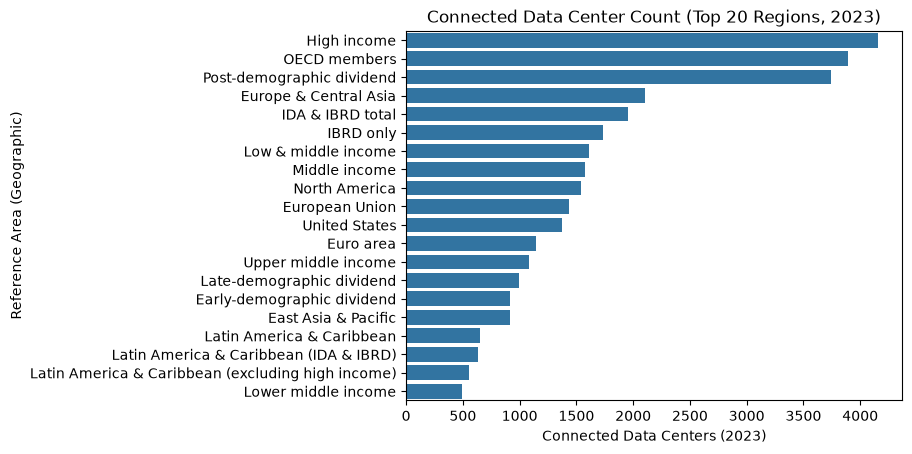

In [5]:
sns.barplot(data=df_bar, x='2023', y='REF_AREA_LABEL')
plt.title("Connected Data Center Count (Top 20 Regions, 2023)")
plt.ylabel("Reference Area (Geographic)")
plt.xlabel("Connected Data Centers (2023)")
plt.show()

In [47]:
# api capture
import requests
import json
import time

api_data = []
counter = 1
while True:
    url = f"https://www.peeringdb.com/api/net/{counter}"
    response = requests.get(url)
    #print(response.text)
    #print(response.get("data", {})[0].get("org", {}))
    if response.status_code == 200:
        response = response.json()
        netixlan_set = response.get("data", {})[0].get("netixlan_set", {})
        #print(response.get("data", {})[0].get("netixlan_set", {}))
        for i in range(len(netixlan_set)):
             api_data.append(netixlan_set[i])
        #api_data.update(response.get("data", {})[0].get("netixlan_set", {}))
        counter += 1
        print(f"Data Collected for {url}")
        time.sleep(15)
    else:
        print(response.text)
        print(f"Error: Request failed for {url} \n Skipping URL")
        counter += 1

    if counter == 6:
        break

Data Collected for https://www.peeringdb.com/api/net/1
{"message": "Request was throttled. Expected available in 35 minutes. Authenticate for less restrictions. For more information: https://docs.peeringdb.com/howto/api_keys/", "meta": {"error": "Too Many Requests"}}
Error: Request failed for https://www.peeringdb.com/api/net/2 
 Skipping URL
Data Collected for https://www.peeringdb.com/api/net/3
Data Collected for https://www.peeringdb.com/api/net/4
Data Collected for https://www.peeringdb.com/api/net/5


AttributeError: 'DataFrame' object has no attribute 'concat'

In [72]:
api_df = pd.DataFrame(api_data)

In [73]:
api_df

,id,ix_id,name,ixlan_id,notes,speed,asn,ipaddr4,ipaddr6,is_rs_peer,bfd_support,operational,net_side_id,ix_side_id,meta,created,updated,status
0,81,64,NL-ix: Main,64,,1000,31800,193.239.116.162,NaN,False,False,True,NaN,104.0,{},2010-07-29T00:00:00Z,2024-11-29T10:44:41Z,ok
1,84,3,Equinix Dallas,3,,1000,31800,206.223.118.88,NaN,False,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2016-03-14T21:02:11Z,ok
2,86,5,Equinix San Jose,5,,1000,31800,206.223.116.138,NaN,False,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2016-03-14T21:02:11Z,ok
3,92,22,Digital Realty Atlanta,22,,1000,31800,206.126.110.25,NaN,False,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2024-07-24T16:29:04Z,ok
4,95,94,Equinix Sydney,94,,100,31800,45.127.172.27,NaN,True,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2018-03-14T05:25:26Z,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,101297,4705,nine,4705,,100000,3303,185.1.14.40,2001:7f8:12e::3303:2,True,False,False,226.0,226.0,{},2025-07-04T07:27:50Z,2026-10-20T02:11:36Z,not-operational
81,102197,319,SIX SI,319,,10000,3303,91.220.194.43,2001:7f8:46:0:1::3303,True,False,True,NaN,882.0,{},2025-08-12T06:33:24Z,2026-03-26T16:03:35Z,ok
82,110841,488,IXPN Lagos,488,,300,3303,196.216.148.41,2001:43f8:bb1::41,True,False,True,NaN,NaN,{},2026-06-26T14:26:31Z,2026-06-26T14:26:31Z,ok
83,112306,4705,nine,4705,,100000,3303,185.1.14.168,2001:7f8:12e::3303:1,True,False,True,53.0,53.0,{},2026-08-17T17:18:59Z,2026-10-19T17:11:23Z,ok


In [74]:
import requests
import pandas as pd

url = "https://www.peeringdb.com/api/netixlan"

api_data = []

for offset in range(0, 2500, 250):
    response = requests.get(
        url,
        params={
            "limit": 250,
            "skip": offset,
            "status": "ok"
        },
        timeout=30
    )
    response.raise_for_status()

    batch = response.json()["data"]

    if not batch:
        break

    api_data.extend(batch)

api_df = pd.DataFrame(api_data)

print(api_df.shape)

(2500, 19)


In [75]:
api_df

,id,net_id,ix_id,name,ixlan_id,notes,speed,asn,ipaddr4,ipaddr6,is_rs_peer,bfd_support,operational,net_side_id,ix_side_id,meta,created,updated,status
0,13,694,12,Equinix New York,12,,100000,8075,198.32.118.91,2001:504:f::8075:2,False,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2021-09-02T17:12:24Z,ok
1,38,2,13,SIX Seattle: MTU 1500,13,,400000,20940,206.81.80.113,2001:504:16::51cc,True,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2026-01-09T17:41:03Z,ok
2,68,2,73,MegaIX Munich,73,,100000,20940,194.59.190.59,2001:7f8:2c:1000:0:51cc:0:1,True,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2017-12-01T12:38:22Z,ok
3,81,3,64,NL-ix: Main,64,,1000,31800,193.239.116.162,NaN,False,False,True,NaN,104.0,{},2010-07-29T00:00:00Z,2024-11-29T10:44:41Z,ok
4,84,3,3,Equinix Dallas,3,,1000,31800,206.223.118.88,NaN,False,False,True,NaN,NaN,{},2010-07-29T00:00:00Z,2016-03-14T21:02:11Z,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,12968,26597,129,JINX: JINX Peering,129,,10000,328829,196.60.96.26,2001:43f8:1f0::26,True,False,True,NaN,2172.0,{},2012-12-16T00:00:00Z,2026-03-26T15:39:43Z,ok
2496,12969,4168,115,TOP-IX: Public Peering VLAN,115,,10000,41090,194.116.96.210,2001:7f8:23:ffff::23,True,False,True,NaN,NaN,{},2012-12-16T00:00:00Z,2021-04-20T06:59:38Z,ok
2497,12970,4294,264,Equinix Warsaw,264,,10000,12578,195.182.219.44,2001:7f8:42::a501:2578:1,True,False,True,NaN,NaN,{},2012-12-16T00:00:00Z,2017-10-20T07:09:57Z,ok
2498,12971,4987,31,DE-CIX Frankfurt: DE-CIX Frankfurt Peering LAN,31,,40000,35805,80.81.192.31,2001:7f8::8bdd:0:1,False,False,True,NaN,NaN,{},2012-12-16T00:00:00Z,2026-05-13T13:39:02Z,ok


In [77]:
import requests
import pandas as pd
import time
import random
import os
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime


def retry_after_seconds(response):
    """Parse Retry-After as seconds or an HTTP date."""
    value = response.headers.get("Retry-After")

    if not value:
        return None

    try:
        return max(0, float(value))
    except ValueError:
        try:
            retry_date = parsedate_to_datetime(value)
            if retry_date.tzinfo is None:
                retry_date = retry_date.replace(tzinfo=timezone.utc)
            return max(
                0,
                (retry_date - datetime.now(timezone.utc)).total_seconds()
            )
        except (ValueError, TypeError, OverflowError):
            return None


def fetch_peeringdb(
    endpoint,
    limit=250,
    max_rows=10000,
    max_retries=5,
    delay=2,
    max_wait=120,
    api_key=None
):
    """
    Fetch PeeringDB data with:
    - Pagination
    - Exponential backoff
    - HTTP 429 handling
    - Network/timeout retries
    - Authentication error handling
    - Partial-result preservation
    """

    records = []
    offset = 0

    session = requests.Session()
    session.headers.update({
        "Accept": "application/json",
        "User-Agent": "AcademicVisualizationProject/1.0"
    })

    api_key = api_key or os.getenv("PEERINGDB_API_KEY")

    if api_key:
        session.headers["Authorization"] = f"Api-Key {api_key}"

    url = f"https://www.peeringdb.com/api/{endpoint}"

    try:
        while offset < max_rows:

            page_limit = min(limit, max_rows - offset)

            params = {
                "limit": page_limit,
                "skip": offset,
                "status": "ok"
            }

            success = False

            for attempt in range(max_retries + 1):

                try:
                    response = session.get(
                        url,
                        params=params,
                        timeout=30
                    )

                    # Rate limited
                    if response.status_code == 429:
                        if attempt == max_retries:
                            print(
                                f"Rate limit persisted after "
                                f"{max_retries + 1} attempts."
                            )
                            break

                        server_wait = retry_after_seconds(response)

                        if server_wait is not None:
                            wait = server_wait
                        else:
                            wait = min(
                                max_wait,
                                5 * (2 ** attempt) + random.uniform(0, 2)
                            )

                        # Avoid silently waiting excessively
                        if wait > max_wait:
                            print(
                                f"Server requested {wait:.1f}s wait; "
                                "stopping this download."
                            )
                            break

                        print(
                            f"429: Rate limited. "
                            f"Retrying in {wait:.1f}s "
                            f"(attempt {attempt + 1}/{max_retries})"
                        )

                        time.sleep(wait)
                        continue

                    # Authentication or permission failures
                    if response.status_code in (401, 403):
                        print(
                            f"Access refused ({response.status_code}). "
                            "Check API credentials or permissions."
                        )
                        break

                    # Other temporary server failures
                    if response.status_code in (500, 502, 503, 504):
                        if attempt == max_retries:
                            break

                        wait = retry_after_seconds(response)

                        if wait is None:
                            wait = min(
                                max_wait,
                                2 ** attempt + random.uniform(0, 2)
                            )

                        if wait > max_wait:
                            break

                        print(
                            f"Server error {response.status_code}. "
                            f"Retrying in {wait:.1f}s."
                        )

                        time.sleep(wait)
                        continue

                    # Other HTTP errors should not be retried
                    response.raise_for_status()

                    payload = response.json()
                    batch = payload.get("data")

                    if not isinstance(batch, list):
                        raise ValueError(
                            "Unexpected API response: "
                            "'data' is missing or is not a list."
                        )

                    records.extend(batch)
                    offset += len(batch)

                    print(
                        f"[{endpoint}] Fetched {len(batch)} rows | "
                        f"Total: {len(records)}"
                    )

                    success = True
                    break

                except (
                    requests.exceptions.Timeout,
                    requests.exceptions.ConnectionError
                ) as e:
                    if attempt == max_retries:
                        print(f"Network failure: {e}")
                        break

                    wait = min(
                        max_wait,
                        2 ** attempt + random.uniform(0, 2)
                    )

                    print(
                        f"Connection issue. Retrying in {wait:.1f}s."
                    )
                    time.sleep(wait)

                except (
                    requests.exceptions.HTTPError,
                    requests.exceptions.JSONDecodeError,
                    ValueError
                ) as e:
                    print(f"Request failed: {e}")
                    break

            if not success:
                print(
                    f"Stopped at offset {offset}. "
                    f"Preserved {len(records)} previously fetched rows."
                )
                break

            # End of available data
            if len(batch) < page_limit:
                print(f"[{endpoint}] End of dataset reached.")
                break

            # Polite delay between successful requests
            if offset < max_rows:
                time.sleep(delay + random.uniform(0, 0.5))

    finally:
        session.close()

    df = pd.DataFrame(records)

    if "id" in df.columns:
        df = df.drop_duplicates(subset="id")

    print(f"\nFinished {endpoint}: {df.shape}")

    return df

In [78]:
net_df = fetch_peeringdb(
    "net",
    limit=250,
    max_rows=10000,
    delay=3
)

[net] Fetched 250 rows | Total: 250
[net] Fetched 250 rows | Total: 500
[net] Fetched 250 rows | Total: 750
[net] Fetched 250 rows | Total: 1000
[net] Fetched 250 rows | Total: 1250
[net] Fetched 250 rows | Total: 1500
[net] Fetched 250 rows | Total: 1750
[net] Fetched 250 rows | Total: 2000
[net] Fetched 250 rows | Total: 2250
[net] Fetched 250 rows | Total: 2500
[net] Fetched 250 rows | Total: 2750
[net] Fetched 250 rows | Total: 3000
[net] Fetched 250 rows | Total: 3250
[net] Fetched 250 rows | Total: 3500
[net] Fetched 250 rows | Total: 3750
[net] Fetched 250 rows | Total: 4000
[net] Fetched 250 rows | Total: 4250
[net] Fetched 250 rows | Total: 4500
[net] Fetched 250 rows | Total: 4750
[net] Fetched 250 rows | Total: 5000
[net] Fetched 250 rows | Total: 5250
[net] Fetched 250 rows | Total: 5500
[net] Fetched 250 rows | Total: 5750
[net] Fetched 250 rows | Total: 6000
[net] Fetched 250 rows | Total: 6250
[net] Fetched 250 rows | Total: 6500
[net] Fetched 250 rows | Total: 6750
[net

In [79]:
net_df.head()

,id,org_id,name,aka,name_long,website,social_media,asn,looking_glass,route_server,...,allow_ixp_update,ixp_update_exclude,status_dashboard,rir_status,rir_status_updated,logo,meta,created,updated,status
0,1,8897,GTT Communications (AS4436),Formerly known as nLayer Communications,,http://www.gtt.net,"[{'service': 'website', 'identifier': 'http://...",4436,,,...,False,[],NaN,ok,2024-06-26T04:47:55Z,NaN,{},2004-07-28T00:00:00Z,2022-07-27T05:33:22Z,ok
1,2,14,Akamai Technologies,,,https://www.akamai.com/,"[{'service': 'website', 'identifier': 'https:/...",20940,,,...,False,[],https://www.akamaistatus.com/,ok,2024-06-26T04:47:55Z,NaN,{},2004-07-28T00:00:00Z,2026-10-23T13:53:15Z,ok
2,3,17,DALnet IRC Network,,,http://www.dal.net,"[{'service': 'website', 'identifier': 'http://...",31800,,,...,False,[],,ok,2024-06-26T04:47:55Z,NaN,{},2004-07-28T00:00:00Z,2026-03-25T13:20:20Z,ok
3,5,9350,Swisscom,IP-Plus,,http://www.swisscom.com,"[{'service': 'website', 'identifier': 'http://...",3303,,telnet://route-server.ip-plus.net,...,False,[],,ok,2024-06-26T04:47:55Z,NaN,{},2004-07-28T00:00:00Z,2026-10-19T17:16:02Z,ok
4,6,23,Cox Communications,Cox Communications,,http://www.cox.com/peering,"[{'service': 'website', 'identifier': 'http://...",22773,,,...,False,[],,ok,2024-06-26T04:47:55Z,NaN,{},2004-07-28T00:00:00Z,2022-11-28T22:55:17Z,ok


In [80]:
ix_df = fetch_peeringdb(
    "ix",
    limit=250,
    max_rows=10000,
    delay=3
)

[ix] Fetched 250 rows | Total: 250
[ix] Fetched 250 rows | Total: 500
[ix] Fetched 250 rows | Total: 750
[ix] Fetched 250 rows | Total: 1000
[ix] Fetched 250 rows | Total: 1250
[ix] Fetched 82 rows | Total: 1332
[ix] End of dataset reached.

Finished ix: (1332, 35)


In [81]:
ix_df.head()

,id,org_id,name,aka,name_long,city,country,region_continent,media,notes,...,ixf_last_import,ixf_import_request,ixf_import_request_status,service_level,terms,status_dashboard,logo,created,updated,status
0,1,2,Equinix Ashburn,,Equinix Internet Exchange Ashburn,Ashburn,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:34:35Z,ok
1,2,2,Equinix Chicago,,Equinix Internet Exchange Chicago,Chicago,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:35:01Z,ok
2,3,2,Equinix Dallas,,Equinix Internet Exchange Dallas,Dallas,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:35:07Z,ok
3,4,2,Equinix Los Angeles,,Equinix Internet Exchange Los Angeles,Los Angeles,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:36:49Z,ok
4,5,2,Equinix San Jose,,Equinix Internet Exchange San Jose (Bay Area),San Jose,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:38:33Z,ok


In [82]:
netixlan_df = fetch_peeringdb(
    "netixlan",
    limit=250,
    max_rows=20000,
    delay=3
)

[netixlan] Fetched 250 rows | Total: 250
[netixlan] Fetched 250 rows | Total: 500
[netixlan] Fetched 250 rows | Total: 750
[netixlan] Fetched 250 rows | Total: 1000
[netixlan] Fetched 250 rows | Total: 1250
[netixlan] Fetched 250 rows | Total: 1500
[netixlan] Fetched 250 rows | Total: 1750
[netixlan] Fetched 250 rows | Total: 2000
[netixlan] Fetched 250 rows | Total: 2250
[netixlan] Fetched 250 rows | Total: 2500
[netixlan] Fetched 250 rows | Total: 2750
[netixlan] Fetched 250 rows | Total: 3000
[netixlan] Fetched 250 rows | Total: 3250
[netixlan] Fetched 250 rows | Total: 3500
[netixlan] Fetched 250 rows | Total: 3750
[netixlan] Fetched 250 rows | Total: 4000
[netixlan] Fetched 250 rows | Total: 4250
[netixlan] Fetched 250 rows | Total: 4500
[netixlan] Fetched 250 rows | Total: 4750
[netixlan] Fetched 250 rows | Total: 5000
[netixlan] Fetched 250 rows | Total: 5250
[netixlan] Fetched 250 rows | Total: 5500
[netixlan] Fetched 250 rows | Total: 5750
[netixlan] Fetched 250 rows | Total: 